In [2]:
import json
from pathlib import Path
import re
import pandas as pd


def clean_player_name(name: str) -> str:
  if not name or not isinstance(name, str):
    return ''
  clean = re.sub(r'\s*-\s*-', '', name).strip()
  return clean


def load_all_games(
    processed_dir: str = 'data/processed',
) -> tuple[pd.DataFrame, pd.DataFrame]:
  path = Path(processed_dir)
  games_list = []
  player_stats_list = []

  for json_file in path.glob('match_*.json'):
    with open(json_file, 'r', encoding='utf-8') as f:
      data = json.load(f)

    meta = data.get('metadata', {})
    match_id = json_file.stem.replace('match_', '')

    games_list.append({
        'match_id': match_id,
        'game_number': meta.get('game_number', ''),
        'date': meta.get('date', ''),
        'home_team': meta.get('home_team', ''),
        'away_team': meta.get('away_team', ''),
        'final_score': meta.get('final_score', ''),
        'spectators': meta.get('spectators', 0),
    })

    # Beide Kader (Heim und Gast) vollständig verarbeiten
    for team_type, kader_key in [
        ('Heim', 'home_kader'),
        ('Gast', 'away_kader'),
    ]:
      kader = data.get(kader_key, [])
      team_name = meta.get(
          'home_team' if team_type == 'Heim' else 'away_team', ''
      )

      for p in kader:
        raw_name = p.get('Name', '')
        name = clean_player_name(raw_name)

        nr = str(p.get('Nr', '')).strip()
        if not name or nr in ['A', 'B', 'C', 'D', 'H']:
          continue

        # Tore auslesen
        tore_str = str(p.get('Tore', '')).strip()
        tore = int(tore_str) if tore_str.isdigit() else 0

        # 7m Tore auslesen
        seven_m_str = str(p.get('7m_Tore', '')).strip()
        seven_m_goals = 0
        if '/' in seven_m_str:
          try:
            seven_m_goals = int(seven_m_str.split('/')[0])
          except ValueError:
            seven_m_goals = 0

        player_stats_list.append({
            'match_id': match_id,
            'team': team_name,
            'nr': nr,
            'person': name,
            'tore': tore,
            '7m_tore': seven_m_goals,
        })

  games_df = pd.DataFrame(games_list)
  player_stats_df = pd.DataFrame(player_stats_list)

  return games_df, player_stats_df

,home_team,Heimspiele,Zuschauer_Gesamt,Zuschauer_Schnitt
1,FRANKFURTER HC,3,1103,367.7
9,TUS 97 BIELEFELD/JÖLLENBECK,3,963,321.0
4,HSG EIDER HARDE,3,852,284.0
6,SV FORTUNA 50 NEUBRANDENBURG,2,480,240.0
5,SC SFN VECHTA,3,660,220.0
7,SV GRÜN WEISS SCHWERIN,1,199,199.0
10,TV HANNOVER-BADENSTEDT,2,317,158.5
8,TSV NORD HARRISLEE,2,256,128.0
0,BUXTEHUDER SV II,2,246,123.0
3,HSG BLOMBERG-LIPPE 2,3,351,117.0


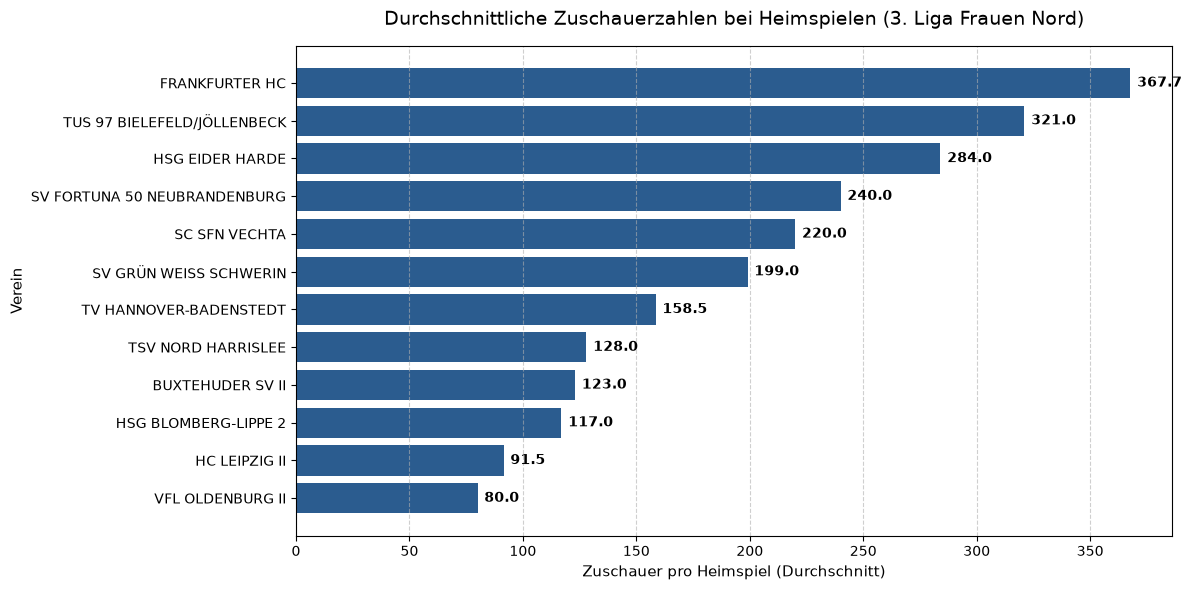

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from src.analytics import load_all_games

# 1. Daten aus allen aufbereiteten Spielen laden
games_df, _ = load_all_games()

# 2. Spiele mit gültigen Zuschauerangaben (> 0) filtern
valid_games = games_df[games_df["spectators"] > 0].copy()

# 3. Durchschnitt, Gesamtzahl und Anzahl der Heimspiele pro Verein berechnen
spectator_stats = valid_games.groupby("home_team").agg(
    Heimspiele=("spectators", "count"),
    Zuschauer_Gesamt=("spectators", "sum"),
    Zuschauer_Schnitt=("spectators", "mean")
).reset_index()

# Nach dem höchsten Zuschauerschnitt sortieren und runden
spectator_stats = spectator_stats.sort_values(by="Zuschauer_Schnitt", ascending=False)
spectator_stats["Zuschauer_Schnitt"] = spectator_stats["Zuschauer_Schnitt"].round(1)

# 4. Tabelle im Notebook anzeigen
display(spectator_stats)

# 5. Balkendiagramm direkt unter der Zelle ausgeben
plt.figure(figsize=(12, 6))
bars = plt.barh(spectator_stats["home_team"], spectator_stats["Zuschauer_Schnitt"], color="#2b5c8f")

# Werte direkt an den Balken beschriften
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Durchschnittliche Zuschauerzahlen bei Heimspielen (3. Liga Frauen Nord)", fontsize=14, pad=15)
plt.xlabel("Zuschauer pro Heimspiel (Durchschnitt)", fontsize=11)
plt.ylabel("Verein", fontsize=11)
plt.gca().invert_yaxis()  # Höchster Wert ganz oben
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()

# Grafik im Notebook anzeigen
plt.show()